# 1.5 - Manual clustering (tune, eyeball & merge)

Same playground as in the day-based project, on the radius features.

1. Tune `K` and `RADIUS_WEIGHTS` at the top, run top to bottom.
2. Grid: orange = centroid (mean crossing point -> exit at each radius), blue =
   member trajectories after the crossing, grey = before the crossing.
3. Give each cluster a **group letter** in `ASSIGN` (same letter = merged).
4. When happy: set `SAVE_MODEL = True` and re-run the save cell (03 / 04 read
   that model), then paste the printed `GROUP_MAP`, `GROUP_NAMES` and
   `RADIUS_WEIGHTS` into `config.py`.

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath(".."))   # project root: config.py, pipeline.py
import numpy as np
import pandas as pd
import config as C
import pipeline as P
print("project root:", C.PROJECT_ROOT)
print(f"crossing: {C.LAT_CROSS} N | radii (km): {C.RADII_KM}")

import xarray as xr
import matplotlib.pyplot as plt
from sklearn.cluster import MiniBatchKMeans
from sklearn.preprocessing import StandardScaler

# --- TUNE ME -----------------------------------------------------------------
K = 20
# per-radius weights tuned HERE; paste into config.RADIUS_WEIGHTS when final
RADIUS_WEIGHTS = dict(C.RADIUS_WEIGHTS)      # e.g. {200: 0.5, 500: 1.0, 1000: 1.5, 1500: 1.5, 2000: 2.0}
SAVE_MODEL = False                           # True -> write the fit for notebooks 03 / 04
# -----------------------------------------------------------------------------

W = P.feature_weight_vector(RADIUS_WEIGHTS)
print("radii:", C.RADII_KM, "| K:", K, "| weights:", RADIUS_WEIGHTS)

project root: /work/bk1450/b383184/Amazon/Mercator/notebooks/run_2/kmeans_radius
crossing: 2.5 N | radii (km): [200, 500, 1000, 1500, 2000]
radii: [200, 500, 1000, 1500, 2000] | K: 20 | weights: {200: 0.03, 500: 0.17, 1000: 0.66, 1500: 1.5, 2000: 2.65}


## Fit k-means
Standardize each column, apply the radius weights `W`, fit.

In [2]:
features = pd.read_parquet(C.FEATURES_FILE)
# fit on complete AND partial particles (most eastward / retroflection water is partial)
fitset = features[features.status.isin(["complete", "partial"])].reset_index(drop=True)
del features
# direction-balanced sample (see explain_direction_balanced_sampling.ipynb):
# direction = crossing point on 2.5N -> outer point (2000 km exit, or last position);
# compass cut into 24 slices of 15 deg; each particle drawn with chance ~ n_slice**(alpha-1)
#   BALANCE_ALPHA = 1 -> as they come (old 1.5), 0 -> every slice about equal (v2 / v3), 0.5 in between
BALANCE_ALPHA = 0.0
b = P.bearing_deg(fitset.cross_lat, fitset.cross_lon,
                  fitset[P.lat_col(2000)], fitset[P.lon_col(2000)])
sector = np.clip(np.floor((b + 180) / 15).astype(int), 0, 23)
w = np.bincount(sector, minlength=24)[sector].astype(float) ** (BALANCE_ALPHA - 1.0)
idx = np.random.default_rng(C.RANDOM_STATE).choice(len(fitset), size=min(C.N_SUB, len(fitset)),
                                                   replace=False, p=w / w.sum())
sub = fitset.iloc[idx].reset_index(drop=True)
print(f"fit sample: {len(sub):,} of {len(fitset):,} particles (complete + partial), alpha = {BALANCE_ALPHA}; "
      f"eastward share: sample {100 * (b[idx] > 0).mean():.1f}%, all {100 * (b > 0).mean():.1f}%")

X_raw  = P.build_feature_matrix(sub)
scaler = StandardScaler().fit(X_raw)
X_sub  = scaler.transform(X_raw) * W

km = MiniBatchKMeans(n_clusters=K, random_state=C.RANDOM_STATE,
                     batch_size=10000, n_init=100, max_iter=300)
labels = km.fit_predict(X_sub)
sizes  = np.bincount(labels, minlength=K)

# centroids in degrees [lat_r0, lon_r0, lat_r1, ...]; start = mean crossing point
cent_deg  = P.centroids_to_degrees(km.cluster_centers_ / W, scaler)
start_lon = sub.groupby(labels).cross_lon.mean().reindex(range(K)).to_numpy()
def centroid_track(c):
    return (np.r_[start_lon[c], cent_deg[c, 1::2]],
            np.r_[C.LAT_CROSS, cent_deg[c, 0::2]])
print(f"fit k={K} on {len(sub):,} particles | cluster sizes {sizes.min()}..{sizes.max()}")

fit sample: 500,000 of 15,068,653 particles (complete + partial), alpha = 0.0; eastward share: sample 40.7%, all 2.4%
fit k=20 on 500,000 particles | cluster sizes 8177..64645


In [3]:
# Persist THIS fit for notebooks 03 / 04 (only when SAVE_MODEL is True).
# The subsample labels keep store / row / traj, so every fitted particle can be
# found again.
import joblib, json
if SAVE_MODEL:
    MODEL_DIR = C.manual_model_dir(K)
    MODEL_DIR.mkdir(parents=True, exist_ok=True)
    joblib.dump(km, MODEL_DIR / f"kmeans_k{K}.pkl")
    joblib.dump(scaler, MODEL_DIR / "scaler.pkl")
    np.save(MODEL_DIR / "weights_W.npy", W)
    np.save(MODEL_DIR / "centroids_deg.npy", cent_deg)
    sub[["trajectory_id", "store", "row", "traj"]].assign(cluster=labels).to_parquet(
        MODEL_DIR / "subsample_labels.parquet", index=False)
    (MODEL_DIR / "fit_metadata.json").write_text(json.dumps(dict(
        source_notebook="1.5_Manual_clustering.ipynb", K=K, LAT_CROSS=C.LAT_CROSS,
        RADII_KM=C.RADII_KM, RADIUS_WEIGHTS={str(k): v for k, v in RADIUS_WEIGHTS.items()},
        N_SUB=C.N_SUB, RANDOM_STATE=C.RANDOM_STATE, n_fitted=int(len(sub)),
        cluster_sizes=sizes.tolist()), indent=2))
    print("saved model ->", MODEL_DIR)
else:
    print("SAVE_MODEL is False -> nothing written")

SAVE_MODEL is False -> nothing written


## Cheap coastline
Coarsest Natural Earth coastline (110 m) as plain line segments, so each panel
is an ordinary axes (fast).

In [4]:
import matplotlib.patches as mpatches

def draw_refs(ax, **kw):
    # reference lines from the day-based notebooks + the 2.5N starting line
    for x in (-70, -60, -40):
        ax.axvline(x, lw=.5, **kw)
    ax.axhline(20, lw=.5, **kw)
    ax.axhline(C.LAT_CROSS, lw=.6, ls="--", color="k")
    ax.add_patch(mpatches.Rectangle(xy=(-55, 5), width=10, height=5, lw=1,
                                    edgecolor="green", facecolor="none"))

import cartopy.feature as cfeature
lon_lim = (C.DOMAIN["lon_min"], C.DOMAIN["lon_max"])
lat_lim = (C.DOMAIN["lat_min"], C.DOMAIN["lat_max"])

_coast = []
for geom in cfeature.COASTLINE.with_scale("110m").geometries():
    for line in getattr(geom, "geoms", [geom]):
        _coast.append((np.asarray(line.xy[0]), np.asarray(line.xy[1])))

def draw_coast(ax):
    for x, y in _coast:
        ax.plot(x, y, "-", color="0.75", lw=.4, zorder=0)
    ax.set_xlim(*lon_lim); ax.set_ylim(*lat_lim)
print("coastline segments:", len(_coast))

coastline segments: 134


## All clusters on one map
Every centroid track (crossing -> outermost radius); number at the end.

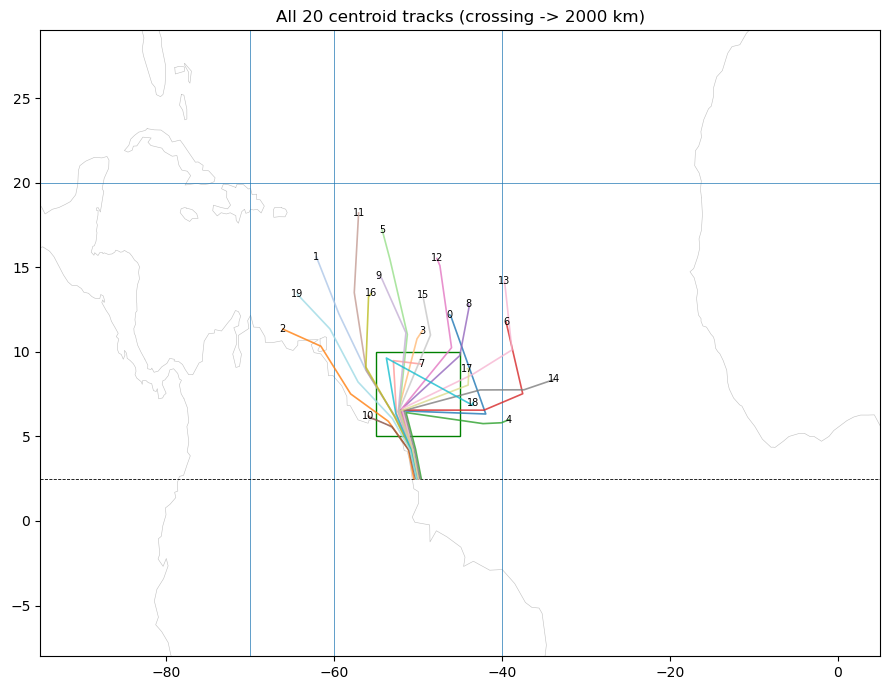

In [5]:
fig, ax = plt.subplots(figsize=(9, 7))
draw_coast(ax); draw_refs(ax)
allcmap = plt.get_cmap("tab20", K)
for c in range(K):
    lo, la = centroid_track(c)
    ax.plot(lo, la, "-", color=allcmap(c), lw=1.2, alpha=.8, zorder=2)
    ax.text(lo[-1], la[-1], str(c), fontsize=7, ha="center", va="center", zorder=4)
ax.set_title(f"All {K} centroid tracks (crossing -> {C.RADII_KM[-1]} km)")
fig.tight_layout(); plt.show()

## Read a few full member trajectories per cluster
`MEMBERS_PER_PANEL` particles per cluster, read by `store` / `row` (checked
against `traj`), each store opened once.

In [6]:
MEMBERS_PER_PANEL = 12
N_IO_THREADS = int(os.environ.get("SLURM_CPUS_PER_TASK", 16))

memdf = sub[["trajectory_id", "store", "row", "traj", "cross_obs"]].assign(lab=labels)
pick = (memdf.groupby("lab", group_keys=False)
             .apply(lambda d: d.sample(min(MEMBERS_PER_PANEL, len(d)),
                                       random_state=C.RANDOM_STATE)))
paths = P.read_paths(pick, n_jobs=N_IO_THREADS)          # trajectory_id -> (lon, lat)
cross_obs = dict(zip(pick.trajectory_id, pick.cross_obs))
members = {c: pick.loc[pick.lab == c, "trajectory_id"].to_numpy() for c in range(K)}
print(f"read {len(paths):,} full trajectories from {pick.store.nunique()} stores (fit sample)")

# --- particles NOT in the fit sample: k-means never saw them, they are only
# assigned to their nearest centroid. If a cluster is real, they follow the
# same route as the fit-sample members (blue) -> drawn in green.
trained = np.zeros(len(fitset), dtype=bool); trained[idx] = True
rest = fitset.loc[~trained, ["trajectory_id", "store", "row", "traj", "cross_obs"]].reset_index(drop=True)
lab_rest = km.predict(scaler.transform(P.build_feature_matrix(fitset.loc[~trained])) * W)
n_rest = np.bincount(lab_rest, minlength=K)          # non-fit particles per cluster
pick_rest = (rest.assign(lab=lab_rest).groupby("lab", group_keys=False)
                 .apply(lambda d: d.sample(min(MEMBERS_PER_PANEL, len(d)), random_state=C.RANDOM_STATE)))
paths.update(P.read_paths(pick_rest, n_jobs=N_IO_THREADS))
cross_obs.update(zip(pick_rest.trajectory_id, pick_rest.cross_obs))
members_rest = {c: pick_rest.loc[pick_rest.lab == c, "trajectory_id"].to_numpy() for c in range(K)}
print(f"read {len(pick_rest):,} non-fit trajectories; {len(rest):,} non-fit particles labelled; "
      f"{int((n_rest == 0).sum())} clusters have no non-fit particle")

/tmp/ipykernel_1144286/2771969228.py:6: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda d: d.sample(min(MEMBERS_PER_PANEL, len(d)),


read 240 full trajectories from 195 stores (fit sample)


/tmp/ipykernel_1144286/2771969228.py:21: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda d: d.sample(min(MEMBERS_PER_PANEL, len(d)), random_state=C.RANDOM_STATE)))


read 240 non-fit trajectories; 14,568,653 non-fit particles labelled; 0 clusters have no non-fit particle


## Assign each cluster a group letter
`ASSIGN[cluster] = "letter"`; same letter => merged. Starts with every cluster
on its own (its number as the label).

In [7]:
ASSIGN = {c: str(c) for c in range(K)}
# ASSIGN = {
#    0: "A1", 1: "B2", ...
# }

## The grid - one panel per cluster

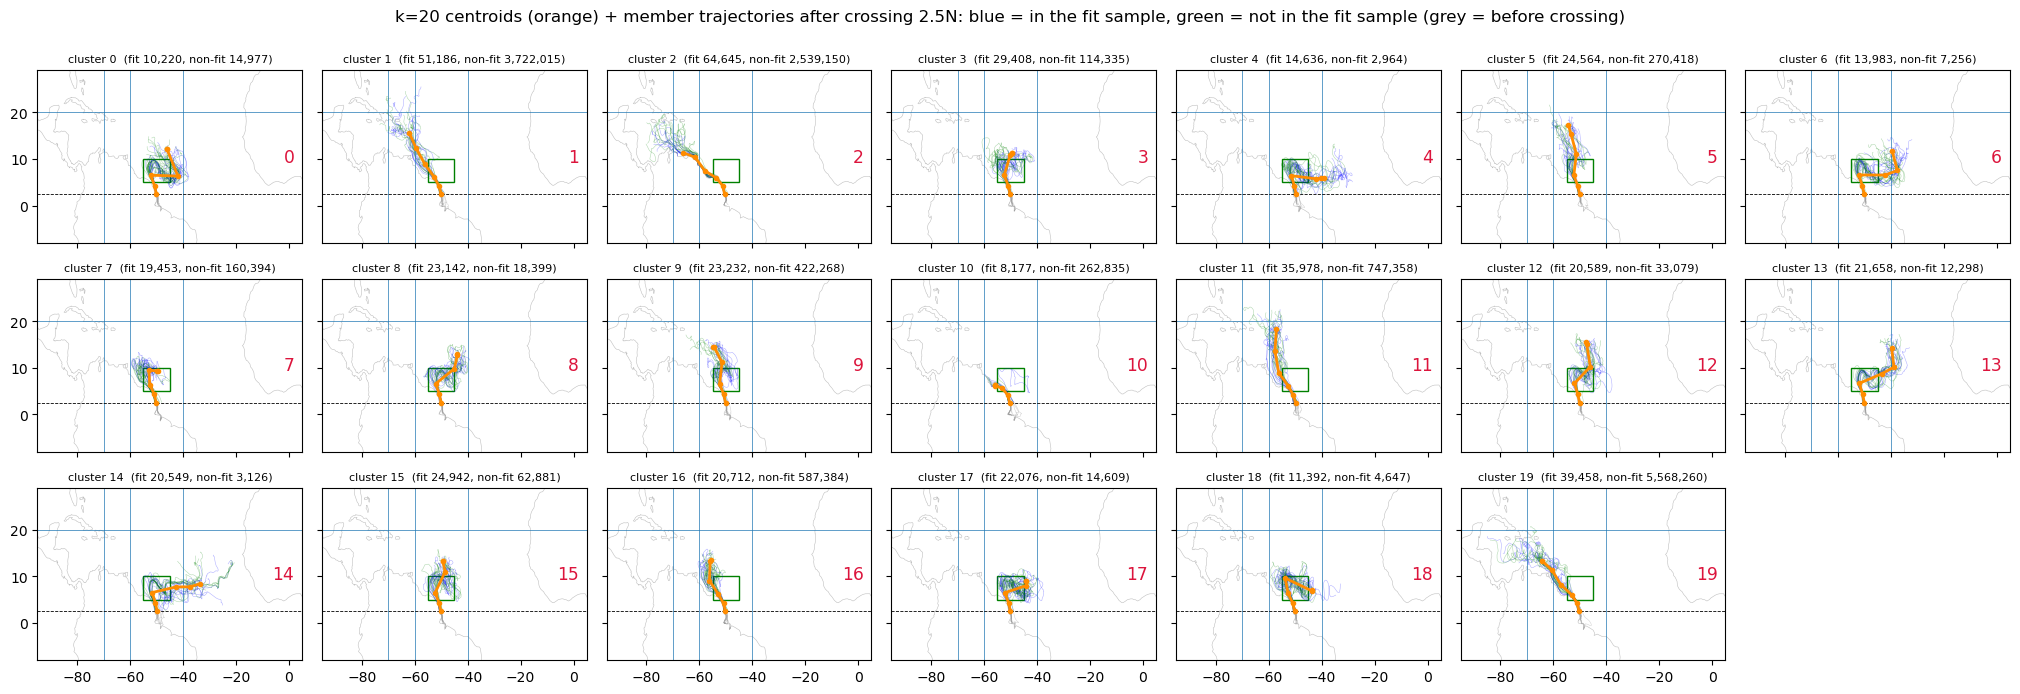

In [8]:
NCOL = 7
LETTER_FRAC = 0.10          # group letter height, as a fraction of the y axis

def draw_cluster(ax, c):
    draw_coast(ax)
    for tid in members[c]:
        lo, la = paths[int(tid)]
        k0 = cross_obs[tid]
        ax.plot(lo[:k0 + 1], la[:k0 + 1], "-", color="0.6", lw=.4, alpha=.4)
        m = ~(np.isnan(lo[k0:]) | np.isnan(la[k0:]))
        ax.plot(lo[k0:][m], la[k0:][m], "-", color="blue", lw=.4, alpha=.3)
    for tid in members_rest[c]:                         # not in the fit sample
        lo, la = paths[int(tid)]
        k0 = cross_obs[tid]
        m = ~(np.isnan(lo[k0:]) | np.isnan(la[k0:]))
        ax.plot(lo[k0:][m], la[k0:][m], "-", color="green", lw=.4, alpha=.3)
    clo, cla = centroid_track(c)
    ax.plot(clo, cla, ".-", color="darkorange", lw=2, zorder=3)

nrow = int(np.ceil(K / NCOL))
fig, axes = plt.subplots(nrow, NCOL, figsize=(2.9 * NCOL, 2.3 * nrow),
                         squeeze=False, sharex=True, sharey=True)
letter_txt = []
for c in range(K):
    ax = axes[c // NCOL][c % NCOL]
    draw_cluster(ax, c); draw_refs(ax)
    ax.set_title(f"cluster {c}  (fit {sizes[c]:,}, non-fit {n_rest[c]:,})", fontsize=8)
    letter_txt.append((ax, ax.text(0.97, 0.5, ASSIGN[c], transform=ax.transAxes,
                                   ha="right", va="center", fontsize=20,
                                   color="crimson", zorder=6)))
for j in range(K, nrow * NCOL):
    axes[j // NCOL][j % NCOL].axis("off")
fig.suptitle(f"k={K} centroids (orange) + member trajectories after crossing {C.LAT_CROSS}N: "
             f"blue = in the fit sample, green = not in the fit sample (grey = before crossing)", y=1.0)
fig.tight_layout()

fig.canvas.draw()
rend = fig.canvas.get_renderer()
for ax, txt in letter_txt:
    h_ax, h_txt = ax.get_window_extent(rend).height, txt.get_window_extent(rend).height
    txt.set_fontsize(txt.get_fontsize() * (LETTER_FRAC * h_ax / h_txt))
fig.canvas.draw()
# fig.savefig(f"cluster_K{K}_W_{RADIUS_WEIGHTS}.pdf", dpi=130, bbox_inches="tight")
plt.show()

## Preview the merged groups
One panel per letter with every centroid assigned to it: first coloured by
cluster, then by radius (dark = 200 km, yellow = outermost).

In [ ]:
letters = sorted(set(ASSIGN.values()))
NCOLg = min(4, len(letters))
nrowg = int(np.ceil(len(letters) / NCOLg))
cmap  = plt.get_cmap("tab20", K)

fig, axes = plt.subplots(nrowg, NCOLg, figsize=(3.4 * NCOLg, 2.7 * nrowg),
                         squeeze=False, sharex=True, sharey=True)
for i, L in enumerate(letters):
    ax = axes[i // NCOLg][i % NCOLg]
    draw_coast(ax); draw_refs(ax)
    mem = [c for c in range(K) if ASSIGN[c] == L]
    for c in mem:
        lo, la = centroid_track(c)
        ax.plot(lo, la, "-", color=cmap(c), lw=1.6, zorder=2)
        ax.plot(lo[-1], la[-1], "o", color=cmap(c), mec="k", ms=5, zorder=3)
        off = [(5, 4), (5, -8), (-13, 4), (-13, -8)][mem.index(c) % 4]
        ax.annotate(str(c), (lo[-1], la[-1]), xytext=off, textcoords="offset points",
                    fontsize=6.5, color="0.1", zorder=5)
    ax.set_title(f"group {L}  ({len(mem)} clusters)", fontsize=9)
for j in range(len(letters), nrowg * NCOLg):
    axes[j // NCOLg][j % NCOLg].axis("off")
fig.suptitle("Merged groups (centroids, coloured by cluster)", y=1.0)
fig.tight_layout(); plt.show()

In [ ]:
rcmap = plt.get_cmap("plasma", len(C.RADII_KM) + 1)
rcol  = [rcmap(i) for i in range(len(C.RADII_KM))]

fig, axes = plt.subplots(nrowg, NCOLg, figsize=(3.4 * NCOLg, 2.7 * nrowg),
                         squeeze=False, sharex=True, sharey=True)
for i, L in enumerate(letters):
    ax = axes[i // NCOLg][i % NCOLg]
    draw_coast(ax); draw_refs(ax)
    mem = [c for c in range(K) if ASSIGN[c] == L]
    for c in mem:
        lo, la = centroid_track(c)
        ax.plot(lo, la, "-", color="0.7", lw=1.0, zorder=2)
        ax.scatter(lo[1:], la[1:], c=rcol, s=26, zorder=3, edgecolor="white", linewidths=.5)
        off = [(5, 4), (5, -8), (-13, 4), (-13, -8)][mem.index(c) % 4]
        ax.annotate(str(c), (lo[-1], la[-1]), xytext=off, textcoords="offset points",
                    fontsize=6.5, color="0.1", zorder=5,
                    bbox=dict(boxstyle="round,pad=0.12", fc="white", ec="none", alpha=.65))
    ax.set_title(f"group {L}  ({len(mem)} clusters)", fontsize=9)
for j in range(len(letters), nrowg * NCOLg):
    axes[j // NCOLg][j % NCOLg].axis("off")
handles = [plt.Line2D([], [], marker=".", ls="", color=rcol[i], mec="white", ms=7,
                      label=f"{r} km") for i, r in enumerate(C.RADII_KM)]
fig.legend(handles=handles, loc="lower center", ncol=len(C.RADII_KM), frameon=False,
           bbox_to_anchor=(0.5, -0.015))
fig.suptitle("Merged groups (centroids, coloured by radius)", y=1.0)
fig.tight_layout(); plt.show()

In [ ]:
from itertools import combinations
def cdist(a, b):            # distance between two centroid tracks (degrees, all radii)
    return float(np.sqrt(((cent_deg[a] - cent_deg[b]) ** 2).sum()))

print("group  n  max_within_dist(deg)  members")
for L in letters:
    m = [c for c in range(K) if ASSIGN[c] == L]
    spread = max((cdist(a, b) for a, b in combinations(m, 2)), default=0.0)
    flag = "  <-- loose?" if spread > 12 else ""
    print(f"  {L:4s} {len(m):2d}      {spread:6.1f}            {m}{flag}")

print("\nclosest different-label cluster pairs (merge/boundary candidates):")
pairs = sorted((cdist(a, b), a, b) for a, b in combinations(range(K), 2) if ASSIGN[a] != ASSIGN[b])
for d, a, b in pairs[:12]:
    print(f"  {d:5.1f} deg : {a}({ASSIGN[a]})  <->  {b}({ASSIGN[b]})")

## Distance of every cluster from the `REF_GROUP` centroids
One row per radius (y axis = where the `REF_GROUP` mean centroid exits that
circle); x = how far every other centroid's exit point is from it, in degrees.
Where a line pulls away marks where that pathway stops following `REF_GROUP`.

In [ ]:
REF_GROUP = letters[0]          # any label used in ASSIGN

tracks = cent_deg.reshape(K, len(C.RADII_KM), 2)          # (K, radius, [lat, lon])
ref_members = [c for c in range(K) if ASSIGN[c] == REF_GROUP]
ref = tracks[ref_members].mean(axis=0)
dist = np.sqrt(((tracks - ref) ** 2).sum(axis=2))          # (K, radius) degrees

broad = sorted({ASSIGN[c][0] for c in range(K)})
PAL = ["#0072B2", "#E69F00", "#009E73", "#D55E00", "#CC79A7", "#56B4E9", "#F0E442", "#000000"]
color = {L: PAL[i % len(PAL)] for i, L in enumerate(broad)}

def coord(la, lo):
    return f"({abs(la):.1f}{'N' if la >= 0 else 'S'}, {abs(lo):.1f}{'W' if lo < 0 else 'E'})"

rows = np.arange(len(C.RADII_KM))
fig, ax = plt.subplots(figsize=(8, 6))
for c in range(K):
    if c not in ref_members:
        ax.plot(dist[c], rows, "-o", color=color[ASSIGN[c][0]], lw=1.6, ms=4,
                alpha=.75, mec="white", mew=.6, zorder=2)
for c in ref_members:
    ax.plot(dist[c], rows, "--", color="0.45", lw=1.4, zorder=3)
ax.set_yticks(rows)
ax.set_yticklabels([f"{r} km  {coord(la, lo)}" for r, (la, lo) in zip(C.RADII_KM, ref)], fontsize=9)
ax.invert_yaxis()
ax.set_xlabel(f"distance from the {REF_GROUP} exit point at that radius (degrees)")
ax.set_xlim(left=0); ax.xaxis.grid(True, color="0.88", lw=.6); ax.set_axisbelow(True)
for s in ("top", "right"):
    ax.spines[s].set_visible(False)
for L in broad:
    ax.plot([], [], "-o", color=color[L], lw=1.6, ms=4, label=f"{L}*")
ax.plot([], [], "--", color="0.45", lw=1.4, label=f"{REF_GROUP} (reference)")
ax.legend(loc="upper right", frameon=False, fontsize=8, title="broad group", ncol=2)
ax.set_title(f"Distance of all {K} centroids from {REF_GROUP}", loc="left")
fig.tight_layout(); plt.show()

hdr = "  ".join(f"{r:>6}km" for r in C.RADII_KM)
print(f" clus  grp  {hdr}")
for c in sorted(range(K), key=lambda c: dist[c, -1]):
    print(f" {c:4d}  {ASSIGN[c]:4s} " + "  ".join(f"{v:8.1f}" for v in dist[c]))

In [ ]:
D = np.array([[cdist(a, b) for b in range(K)] for a in range(K)]); np.fill_diagonal(D, np.inf)
bad = [(c, int(D[c].argmin())) for c in range(K) if ASSIGN[c][0] != ASSIGN[int(D[c].argmin())][0]]
print("clusters whose NEAREST neighbour has a different broad letter:")
for c, nn in bad:
    print(f"  {c}({ASSIGN[c]}) -> {nn}({ASSIGN[nn]}) at {D[c, nn]:.1f} deg")
print("none -> broad grouping is clean" if not bad else f"{len(bad)} to check")

## Export -> paste into `config.py`

In [ ]:
name2id     = {L: i for i, L in enumerate(letters)}
GROUP_MAP   = {c: name2id[ASSIGN[c]] for c in range(K)}
GROUP_NAMES = {i: L for L, i in name2id.items()}

print("RADIUS_WEIGHTS =", RADIUS_WEIGHTS)
print("GROUP_MAP =", GROUP_MAP)
print("GROUP_NAMES =", GROUP_NAMES)
print()
for L in letters:
    print(f"  {L}: {[c for c in range(K) if ASSIGN[c] == L]}")